# (DSC555) Implementation and Deployment
Author: Tracey Johnson/
Date: 11-04-2026/
Python version 3.13

This report consolidates all phases of the project into a comprehensive Jupyter Notebook, including data preparation, exploratory analysis, predictive modeling, validation, and dashboard deployment. The notebook integrates narrative discussion, code, visualizations, and results to provide a transparent and reproducible account of the project.

The report structure is based on the CRISP-DM 1.0 framework, a widely used methodology for organizing data science projects (Chapman et al., 2000):

1. Problem Statement
2. Literature Review
3. Dataset Sources
4. Data Preprocessing
5. Exploratory Analysis Findings
6. Modeling Methods 
7. Model Evaluation and Findings
8. Deployment
9. Conclusion
10. References







README: https://github.com/tdjohnson3210-oss/access-barriers-analysis/blob/main/README.md

Access Barriers Analysis Project Repository: https://github.com/tdjohnson3210-oss/access-barriers-analysis



In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

---

## Problem Statement

Access to justice remains an ongoing concern for courts and policymakers, particularly when barriers outside the courtroom may influence an individual's ability to participate in the civil justice system. Transportation accessibility has been identified as a potential barrier for self-represented litigants, especially in communities where long travel distances, limited public transit options, or other mobility challenges may make reaching courthouses more difficult. However, courts generally do not collect transportation-related data, making it difficult to evaluate whether transportation conditions are associated with differences in civil filing activity.

**Problem Statement.** Courts maintain extensive records of civil filings, but have limited means of examining how transportation accessibility and other community characteristics may influence filing patterns across jurisdictions. As a result, the extent to which transportation conditions contribute to differences in civil filing activity remains largely unknown. This project addresses that gap by developing a machine learning model deployment that combines Washington State civil filing data with transportation, demographic, and socioeconomic indicators to forecast filing activity and identify geographic patterns that may warrant further access-to-justice investigation.

---

## Literature Review

### Civil Filings and Access to Justice

Civil courts provide a formal mechanism for resolving disputes involving contracts, property, housing, consumer debt, and other non-criminal matters. As a result, civil filing activity serves as one indicator of how individuals and organizations engage with the justice system. Recent data from the Court Statistics Project indicate that civil filings have increased since 2020, particularly in contract and small claims cases. However, much of this growth has been driven by institutional repeat filers, such as creditors and debt-collection entities, rather than widespread increases in filings by individual litigants (Court Statistics Project, 2026). These trends suggest that filing volume alone may not reflect equal access to civil justice across all populations.

Research consistently shows that many individuals experience civil legal problems but do not pursue formal legal remedies. According to the Legal Services Corporation (2022), 74% of low-income households experienced at least one civil legal problem during the previous year, yet legal assistance was sought for only a fraction of those issues. Financial constraints, limited legal knowledge, and other structural barriers often prevent individuals from engaging with the legal system despite having unmet legal needs. Consequently, differences in filing activity may reflect not only legal need but also barriers that influence an individual's ability to access the courts.

### Transportation Access Barriers

Access-to-justice research has traditionally focused on barriers such as legal costs, availability of legal representation, and legal literacy. In comparison, less attention has been given to transportation access, despite its importance in accessing public services. Transportation can influence an individual's ability to reach courthouses, legal aid providers, self-help centers, and other resources needed to initiate or participate in legal proceedings.

National transportation data suggest that transportation barriers remain relevant for many households. The 2022 National Household Travel Survey found that approximately 10.7 million U.S. households, representing 8.4% of all households, had no vehicle available and relied on alternative transportation options such as public transit, walking, ridesharing, or assistance from others (Bricka et al., 2024). Although telework and online services have reduced some transportation demands, mobility remains essential for accessing many government, healthcare, educational, and legal services.

### Transportation Challenges in Rural Communities

Transportation barriers may be especially significant in rural areas. Rural residents often face longer travel distances, fewer public transportation options, and greater dependence on personal vehicles. Using data from the National Household Travel Survey, Espeland and Rowangould (2024) found that vehicle access was among the strongest predictors of mobility and that households without reliable transportation were more likely to experience unmet travel needs.

These findings are particularly relevant when considering access to courts and legal services. Individuals who must travel substantial distances to reach a courthouse or who lack reliable transportation may face additional challenges when attempting to file a case, attend hearings, or access available legal resources. While transportation barriers have been examined in relation to healthcare, employment, and other essential services, their relationship to civil court participation remains largely unexplored.

### Research Gaps

Community-centered justice research emphasizes understanding legal problems from the perspective of individuals rather than institutions. Existing studies have demonstrated that structural barriers can limit participation in formal legal processes and disproportionately affect low-income and underserved populations (Sandefur et al., 2023). However, relatively little research has looked at whether transportation access influences civil court filing behavior.

Given the relationship between transportation access and participation in other essential services, transportation may represent an overlooked factor affecting engagement with the civil justice system. Examining this relationship may improve understanding of how structural barriers influence access to justice and whether transportation conditions are associated with variation in civil filing rates across communities.

### Research Question

Do transportation barriers contribute to reduced access to civil justice as reflected in county-level civil filing rates?

---

## Dataset Sources

This project combines civil filing data with demographic, socioeconomic, and transportation-related indicators to examine whether transportation barriers are associated with county-level civil filing rates. Data were obtained from multiple public and administrative sources and integrated into a single analytical dataset. The following sections describe each dataset, the variables selected for analysis, and their relevance to the research question.

### American Community Survey (ACS)

The primary dataset used in this study is derived from the American Community Survey (ACS), an ongoing survey administered by the U.S. Census Bureau that provides annual estimates on demographic, social, economic, housing, and transportation characteristics across the United States. The ACS serves as the foundation of this analysis because it contains community-level measures that may influence access to civil justice, including income, poverty, educational attainment, employment, vehicle availability, internet access, and commuting behavior.

The ACS data were previously collected, cleaned, and transformed into a longitudinal analytical dataset spanning multiple years. These variables were used to create features representing transportation access and broader socioeconomic conditions that may be associated with county-level civil filing rates.

### Rural-Urban Commuting Area (RUCA) Classifications

To provide additional geographic context, Rural-Urban Commuting Area (RUCA) classifications developed by the U.S. Department of Agriculture were incorporated into the analysis. RUCA codes classify communities based on population density, urbanization, and commuting patterns, allowing areas to be categorized along a rural-to-urban continuum. Including these classifications helps account for differences in geographic accessibility and community structure that may influence transportation barriers.

The final processed dataset merges ACS estimates with RUCA classifications and other project-specific data sources to create a unified analytical dataset for modeling and analysis. The following code demonstrates how to load the processed dataset for use in the analyses that follow, from the project's GitHub repository.

In [8]:
url = (
    "https://raw.githubusercontent.com/"
    "tdjohnson3210-oss/access-barriers-analysis/main/data_processed"
)

In [ ]:
dfs = []

for i in range(9):
    file_url = f"{url}/df_primary_part_{i}.parquet"
    dfs.append(pd.read_parquet(file_url))

df_primary = pd.concat(
    dfs,
    ignore_index=True
)

In [7]:
df_primary.dtypes

geography                                                                                                   object
households_by_type_total_households_married_couple_family                                                  float64
households_by_type_total_households_cohabiting_couple_household                                            float64
households_by_type_total_households_male_householder_no_spouse/partner_present                             float64
households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone    float64
                                                                                                            ...   
landarea                                                                                                   float64
popdensity                                                                                                 float64
transportation_households_no_vehicle                                            

### Washington State Civil Filing Data

Washington State superior court filing data serve as a secondary dataset in this study and provide the outcome measure used for modeling. Specifically, county-level civil filing rates are used as the target variable to examine whether transportation and community characteristics are associated with variation in court utilization across jurisdictions.

Washington State was selected as the project's pilot site because the data are publicly available, readily accessible, and suitable for integration with the study's demographic and transportation datasets. This approach aligns with purposeful sampling principles, which recognize the value of selecting accessible data sources for exploratory and applied research (Palinkas et al., 2015).

The civil filing data were aggregated and merged with the processed ACS and RUCA datasets using shared geographic identifiers. The resulting analytical dataset combines community characteristics with county-level filing outcomes, allowing the analysis to evaluate whether transportation barriers and related socioeconomic factors are associated with access to civil justice as reflected in civil filing rates.

In [9]:
df_secondary = pd.read_parquet(
    f"{url}/df_secondary.parquet"
)

In [10]:
df_secondary.dtypes

court_county_name    object
court_name           object
year                  int64
civil                 int64
total                 int64
dtype: object

---

## Data Preprocessing

Several preprocessing steps were performed to transform the raw datasets into a consistent, analysis-ready format suitable for exploratory analysis and predictive modeling.

### Primary Dataset Transformation and Standardization

The ACS datasets were originally provided as annual wide-format tables containing demographic, socioeconomic, housing, internet-access, and transportation measures. To prepare the data for analysis, variables were standardized across years by cleaning column names, removing unnecessary margin-of-error fields, and ensuring consistent naming conventions. Geographic identifiers were also standardized to support merging with external datasets.

In addition, relevant variables related to transportation access and community characteristics were retained while nonessential fields were excluded. Data types were reviewed and corrected where necessary to improve consistency and reduce downstream processing issues.

In [11]:
# Geographic identifiers
geo_cols = [
    'geography',
    'year',
    'tract_name',
    'geoid',
    'statefips20',
    'statename20',
    'countyfips20',
    'countycode20',
    'countyname20'
]

# Household / Family Barriers
household_cols = [
    c for c in df_primary.columns
    if c.startswith('households_by_type_')
]

# Education Barriers
education_cols = [
    c for c in df_primary.columns
    if c.startswith('educational_attainment_')
]

# Disability Barriers
disability_cols = [
    c for c in df_primary.columns
    if c.startswith(
        'disability_status_of_the_civilian_noninstitutionalized_population'
    )
]

# Mobility / Residential Stability Barriers
mobility_cols = [
    c for c in df_primary.columns
    if c.startswith('residence_1_year_ago_')
]

# Language Barriers
language_cols = [
    c for c in df_primary.columns
    if c.startswith('language_spoken_at_home_')
]

# Digital Access Barriers
digital_cols = [
    c for c in df_primary.columns
    if c.startswith('computers_and_internet_use_')
]

# Transportation Barriers
transportation_cols = [
    'transportation_households_no_vehicle',
    'transportation_households_one_vehicle',
    'transportation_households_high_vehicle_access'
]

# Geographic Access / Rurality Barriers (numeric only)
rurality_cols = [
    'urbancore',
    'primaryruca',
    'secondaryruca',
    'population',
    'landarea',
    'popdensity'
]

# All barrier categories
barrier_categories = {
    "household": household_cols,
    "education": education_cols,
    "disability": disability_cols,
    "mobility": mobility_cols,
    "language": language_cols,
    "digital": digital_cols,
    "transportation": transportation_cols,
    "rurality": rurality_cols
}

# All model variables
all_barrier_vars = (
    household_cols +
    education_cols +
    disability_cols +
    mobility_cols +
    language_cols +
    digital_cols +
    transportation_cols +
    rurality_cols
)

### Primary Dataset Transformation

After standardization, individual ACS datasets were combined into a single longitudinal dataset spanning multiple years. This process ensured that variables maintained a consistent structure across all periods and allowed trends and relationships to be examined over time rather than within a single year.

### RUCA Processing and Integration

RUCA classifications were processed separately and prepared for integration by standardizing geographic identifiers and retaining fields describing rural and urban characteristics. Once cleaned, the RUCA data were merged with the ACS dataset using census tract geographic identifiers.

### Washington Civil Filing Data Preparation

Washington State superior court filing data were prepared as the outcome dataset for the pilot analysis. County-level filing information was reviewed, organized, and aggregated to support the calculation of civil filing rates. These filing rates serve as the target variable used throughout the modeling process.

### Dataset Integration and Quality Checks

Following preprocessing, the ACS, RUCA, and Washington filing datasets were integrated using shared geographic identifiers. ACS and RUCA data were first linked using census tract `GEOID` values, allowing demographic, socioeconomic, transportation, and rurality measures to be analyzed together. Because the Washington filing data were available at the county level, the tract-level ACS and RUCA data were aggregated and merged with the filing data using county identifiers and year.

Several validation checks were performed throughout the integration process, including assessments of geographic matches, duplicate records, missing values, and variable distributions. Additional reviews were conducted to verify that geographic identifiers aligned correctly across datasets and that key variables retained expected ranges following aggregation and merging. These steps helped ensure that the final analytical dataset was accurate, complete, and suitable for exploratory analysis and predictive modeling.

---

## Exploratory Analysis Findings

Exploratory data analysis (EDA) was conducted to better understand the distributions, relationships, and quality of the variables included in the final analytical dataset. The objective was not only to identify potential data issues but also to evaluate whether transportation barriers appeared related to other community characteristics and civil filing outcomes. These findings informed feature selection, aggregation decisions, and model development.

### Transportation and Access Barrier Relationships

Correlation analysis identified meaningful relationships between transportation measures and several other barrier categories. The strongest relationships were observed between transportation barriers and digital-access, household, educational, and mobility-related measures. These findings suggest that transportation barriers are often associated with broader socioeconomic and access challenges rather than occurring independently.

The results support the idea that communities experiencing transportation difficulties may also face challenges related to internet access, educational attainment, and household resources. Because multiple barrier categories appeared interconnected, a multivariate modeling approach was deemed more appropriate than evaluating transportation measures in isolation.

In [ ]:
from sklearn.preprocessing import StandardScaler

In [34]:
# Rescale barrier category scores before computing correlations
category_scores = pd.DataFrame(index=df_primary.index)

for name, cols in barrier_categories.items():

    available = [c for c in cols if c in df_primary.columns]

    scaled = StandardScaler().fit_transform(
        df_primary[available].fillna(0)
    )

    category_scores[name] = scaled.mean(axis=1)

corr = category_scores.corr()

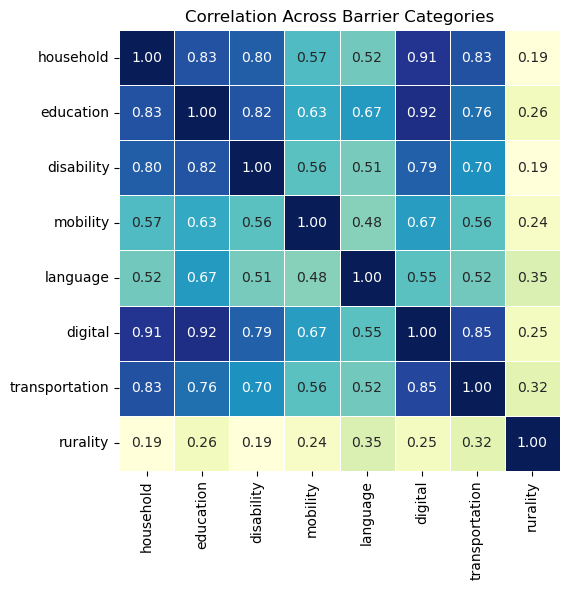

In [33]:
plt.figure(figsize=(7,6))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    square=True,
    linewidths=0.5,
    cbar=False
)

plt.title("Correlation Across Barrier Categories")
plt.tight_layout()
plt.show()

### Community-Level Variation

Descriptive statistics and distributional analyses revealed considerable variation across Washington counties and years. Variables associated with vehicle availability, poverty, internet access, educational attainment, and commuting patterns showed noticeable differences across communities. While some counties exhibited relatively few access challenges, others consistently demonstrated elevated barrier levels across multiple indicators.

These findings indicate that transportation access and related socioeconomic conditions are not evenly distributed throughout Washington State. The observed variability suggested that meaningful differences existed across jurisdictions and supported the inclusion of multiple explanatory variables in subsequent analyses.

In [44]:
df_secondary.describe(include="all")

,court_county_name,court_name,year,civil,total
count,156,156,156.000000,156.000000,156.000000
unique,39,39,NaN,NaN,NaN
top,Adams,Adams County Superior Court,NaN,NaN,NaN
freq,4,4,NaN,NaN,NaN
mean,NaN,NaN,2022.500000,2183.519231,5591.480769
std,NaN,NaN,1.121635,4320.095596,9720.261846
min,NaN,NaN,2021.000000,15.000000,58.000000
25%,NaN,NaN,2021.750000,213.750000,717.500000
50%,NaN,NaN,2022.500000,689.500000,2117.500000
75%,NaN,NaN,2023.250000,1699.250000,5282.000000


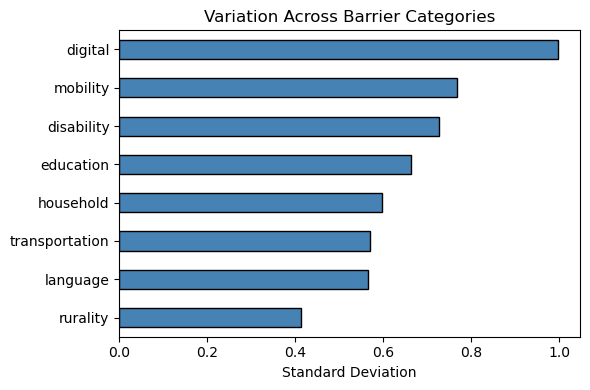

In [36]:
category_scores.std().sort_values().plot.barh(
    figsize=(6,4),
    color="steelblue",
    edgecolor="black"
)

plt.xlabel("Standard Deviation")
plt.ylabel("")
plt.title("Variation Across Barrier Categories")

plt.tight_layout()
plt.show()

### Civil Filing Patterns

Analysis of the Washington State civil filing data revealed substantial differences in filing activity across counties and years. As expected, larger counties generally produced higher filing volumes than smaller counties. However, variation remained even after considering county size, suggesting that additional community characteristics may be associated with filing behavior.

Preliminary review of filing-rate distributions indicated that county-level filing activity was not uniform across the state. These differences provided initial support for exploring whether transportation barriers and related community characteristics could help explain variation in civil filing rates.

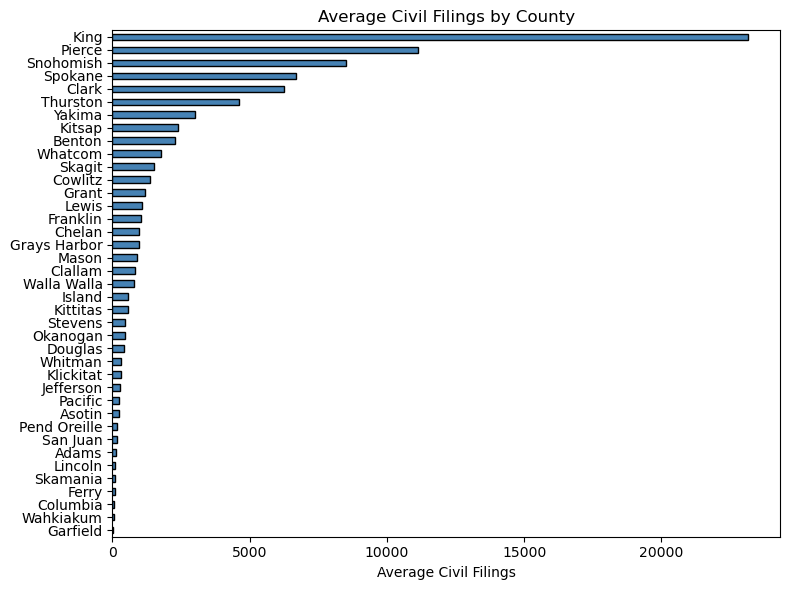

In [41]:
county_filings = (
    df_secondary
    .groupby("court_county_name")["civil"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(8,6))

county_filings.plot.barh(
    color="steelblue",
    edgecolor="black"
)

plt.title("Average Civil Filings by County")
plt.xlabel("Average Civil Filings")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Data Quality and Integration Findings

Several data quality and integration challenges were identified and addressed during preprocessing. ACS tables varied across years and required standardization of column structures, variable names, and geographic identifiers before integration could occur reliably. Geographic validation checks were performed to ensure tract identifiers aligned correctly across ACS and RUCA datasets prior to merging.

Due to the fact that Washington filing data were available at the county level while ACS and RUCA data were available at the tract level, aggregation procedures were required to create a consistent level of analysis. Additional checks were conducted to identify geographic mismatches, duplicate records, unexpected values, and missing data. Overall, few issues remained after preprocessing, providing confidence that the resulting dataset was suitable for analysis.

### Implications for Modeling

The exploratory findings directly informed the modeling strategy used in this study. The observed relationships among transportation, digital, educational, household, mobility, language, and disability barriers supported their inclusion as model features. Variation in county-level filing activity suggested that population and geographic context should also be considered during analysis.

Additionally, the correlation patterns observed during EDA indicated that transportation barriers may be embedded within broader patterns of disadvantage. This finding motivated the use of models capable of evaluating transportation-related measures alongside other community characteristics rather than treating transportation as a standalone predictor. The following sections describe the modeling approaches used to further examine these relationships.

---

## Modeling Methods

Two models were developed to address different components of the research question: How do transportation barriers interact with other access barriers and civil court participation?

### Model 1: Civil Filing Model (Regression)

The first model examined the relationship between transportation barriers and civil filing activity. A multiple linear regression model was selected because civil filings represent a continuous outcome. The target variable was county-level civil filings, while predictor variables included transportation, digital, education, language, disability, household, and mobility barrier scores. Population, population density, and RUCA classifications were also included to account for differences in county size and geographic context.

This model addressed the civil court participation component of the research question by evaluating whether transportation barriers contributed to variation in civil filing activity after controlling for other access barriers and county characteristics. Model performance was evaluated using R², Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE). Regression coefficients and residual diagnostics were also examined to better understand predictor relationships and model fit. The results helped determine whether transportation barriers had an independent relationship with court participation or whether they primarily reflected broader patterns of community disadvantage.

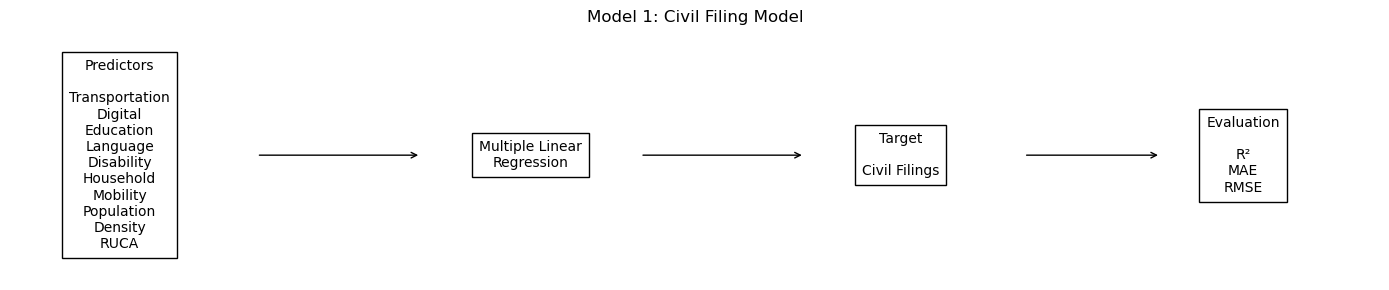

In [ ]:
fig, ax = plt.subplots(figsize=(14, 3))
ax.set_axis_off()
box = dict(
    boxstyle="square,pad=0.5",
    facecolor="white",
    edgecolor="black"
)

ax.text(
    0.08, 0.5,
    "Predictors\n\nTransportation\nDigital\nEducation\nLanguage\nDisability\nHousehold\nMobility\nPopulation\nDensity\nRUCA",
    bbox=box,
    ha="center",
    va="center"
)

ax.text(
    0.38, 0.5,
    "Multiple Linear\nRegression",
    bbox=box,
    ha="center",
    va="center"
)

ax.text(
    0.65, 0.5,
    "Target\n\nCivil Filings",
    bbox=box,
    ha="center",
    va="center"
)

ax.text(
    0.90, 0.5,
    "Evaluation\n\nR²\nMAE\nRMSE",
    bbox=box,
    ha="center",
    va="center"
)

# Simple arrows
for start, end in [(0.18,0.30),(0.46,0.58),(0.74,0.84)]:
    ax.annotate(
        "",
        xy=(end,0.5),
        xytext=(start,0.5),
        arrowprops=dict(
            arrowstyle="->",
            lw=1,
            color="black"
        )
    )

plt.title("Model 1: Civil Filing Model")
plt.tight_layout()
plt.show()

### Model 2: Transportation Risk Classification

The second model examined how transportation risk overlaps with other access barriers. A Random Forest classification model was selected because the objective was to classify observations into transportation risk categories rather than predict a continuous value. Transportation scores were grouped into five risk categories ranging from Very Low to Very High transportation risk, which served as the target variable. Digital, education, language, disability, household, and mobility barrier scores were used as predictors.

This model addressed the barrier interaction component of the research question by determining whether transportation risk could be identified from patterns observed in other access barriers. Model performance was evaluated using accuracy, precision, recall, F1-score, confusion matrices, and feature importance measures. Feature importance results were used to identify which barriers were most strongly associated with transportation risk and to better understand how transportation barriers relate to broader access-to-justice challenges. 【1-7f31b8】【2-b56e1f】

Together, the models provided two complementary perspectives on access to justice. The regression model examined whether transportation barriers were associated with civil court participation, while the classification model examined how transportation barriers interact with digital, educational, language, disability, household, and mobility barriers. This approach allowed transportation barriers to be studied both as a potential influence on civil filings and as part of a broader network of access-related challenges. 【1-7f31b8】【2-b56e1f】

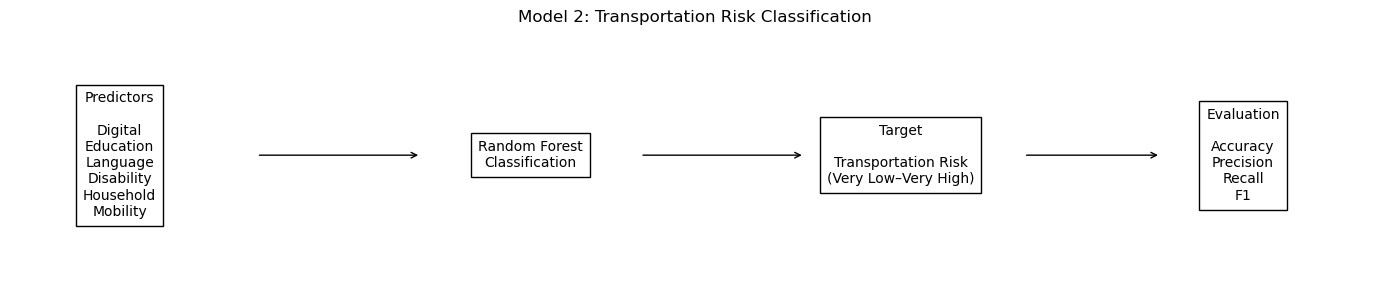

In [21]:
fig, ax = plt.subplots(figsize=(14, 3))
ax.set_axis_off()
box = dict(
    boxstyle="square,pad=0.5",
    facecolor="white",
    edgecolor="black"
)

ax.text(
    0.08, 0.5,
    "Predictors\n\nDigital\nEducation\nLanguage\nDisability\nHousehold\nMobility",
    bbox=box,
    ha="center",
    va="center"
)

ax.text(
    0.38, 0.5,
    "Random Forest\nClassification",
    bbox=box,
    ha="center",
    va="center"
)

ax.text(
    0.65, 0.5,
    "Target\n\nTransportation Risk\n(Very Low–Very High)",
    bbox=box,
    ha="center",
    va="center"
)

ax.text(
    0.90, 0.5,
    "Evaluation\n\nAccuracy\nPrecision\nRecall\nF1",
    bbox=box,
    ha="center",
    va="center"
)

for start, end in [(0.18,0.30),(0.46,0.58),(0.74,0.84)]:
    ax.annotate(
        "",
        xy=(end,0.5),
        xytext=(start,0.5),
        arrowprops=dict(
            arrowstyle="->",
            lw=1,
            color="black"
        )
    )

plt.title("Model 2: Transportation Risk Classification")
plt.tight_layout()
plt.show()

---

## Model Evaluation and Findings

### Model 1: Civil Filing Model

The regression model was evaluated using R², Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), coefficient analysis, and residual diagnostics. The final multiple linear regression model explained approximately 89% of the variation in civil filings (R² = 0.895), indicating strong overall model fit. Population was the strongest predictor of filing activity, while rurality also contributed to explaining variation across counties. Transportation barriers were not statistically significant after controlling for the other barrier measures, suggesting substantial overlap among transportation, digital, and education barriers. Residual analysis showed that most observations were predicted accurately, although several county-year observations exhibited larger prediction errors, indicating that factors not included in the model may also influence filing activity.

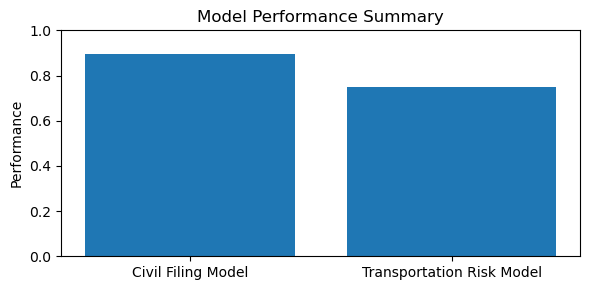

In [ ]:
results = pd.DataFrame({
    "Model": ["Civil Filing Model", "Transportation Risk Model"],
    "Performance": [0.895, 0.75]
})

fig, ax = plt.subplots(figsize=(6,3))

ax.bar(results["Model"], results["Performance"])
ax.set_ylabel("Performance")
ax.set_ylim(0,1)
ax.set_title("Model Performance Summary")

plt.tight_layout()
plt.show()

### Model 2: Transportation Risk Classification

Model 2 was evaluated using accuracy, precision, recall, F1-score, confusion matrices, and feature importance measures. The Random Forest classifier achieved an overall accuracy of approximately 75%, indicating strong performance in identifying transportation risk categories. The model performed best when classifying the Very Low, Low, and Moderate transportation risk groups, while the High risk category proved more difficult to distinguish. Feature importance analysis identified digital barriers as the strongest predictor of transportation risk, followed by education, household, and mobility barriers. Hyperparameter tuning produced nearly identical performance metrics, suggesting that increasing model complexity did not meaningfully improve classification accuracy.

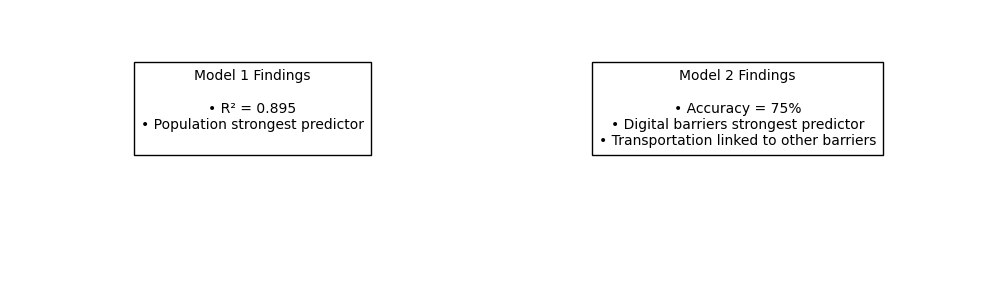

In [46]:
fig, ax = plt.subplots(figsize=(10,3))
ax.axis("off")
box = dict(boxstyle="square,pad=0.5",
           facecolor="white",
           edgecolor="black")

ax.text(
    0.25, 0.5,
    "Model 1 Findings\n\n"
    "• R² = 0.895\n"
    "• Population strongest predictor\n",
    bbox=box,
    ha="center"
)

ax.text(
    0.75, 0.5,
    "Model 2 Findings\n\n"
    "• Accuracy = 75%\n"
    "• Digital barriers strongest predictor\n"
    "• Transportation linked to other barriers",
    bbox=box,
    ha="center"
)

plt.tight_layout()
plt.show()

### Key Findings

Together, the models suggest that transportation barriers are part of a broader access-disadvantage environment rather than an isolated challenge. The regression model showed that transportation barriers alone did not explain variation in civil filing activity after accounting for other barriers and county characteristics. The classification model demonstrated that transportation risk is strongly associated with digital, educational, household, and mobility barriers, indicating that transportation challenges frequently occur alongside other access-related disadvantages.

The modeling results support the use of transportation barriers as a component of a broader access-to-justice monitoring framework. The regression model identified variables most strongly associated with civil filing activity, while the classification model provided a method for identifying Washington counties with elevated transportation risk. These findings informed the design of the dashboard by highlighting transportation risk alongside related barrier categories, allowing users to explore potential access gaps, compare communities, and identify areas where multiple barriers may affect participation in the civil justice system. The models therefore serve as both analytical tools and decision-support components that can guide future dashboard enhancements.

---

## Dashboard Deployment

The final phase of the project focused on deploying the analytical outputs within an interactive Streamlit dashboard. The application was organized and hosted through a public GitHub repository containing the primary application file (`app.py`), a `requirements.txt` file for dependency management, processed datasets, and supporting documentation. 

The dashboard integrates outputs from both predictive models developed during the analysis phase. The multiple linear regression model was packaged and saved for deployment, allowing predicted civil filing activity to be displayed alongside observed filing counts. This output is presented as the **Projected Civil Filings** metric, which represents the expected level of filing activity based on a county's barrier profile, population characteristics, and geographic context.

The Random Forest classification model was also packaged and saved as part of the deployment workflow. Model outputs are used to generate the **Transportation Risk** metric, which classifies counties into transportation-risk categories ranging from Very Low to Very High. These categories provide a more interpretable representation of transportation disadvantage and support comparisons across counties.

Several dashboard metrics were designed to combine model outputs with contextual information. **Actual Civil Filings** represents observed filing activity, **Projected Civil Filings** represents model-estimated filing activity, **Transportation Risk** reflects the classification model output, and **Statewide Rank** provides a relative comparison of filing activity across Washington counties. Additional dashboard components summarize transportation, digital, education, language, disability, household, and mobility barriers to provide a broader view of potential access challenges.

Together, the deployed models support dashboard functionality by generating projected civil filings and transportation risk classifications. These outputs allow users to compare counties across filing activity, transportation risk, and broader access-barrier profiles, helping identify geographic disparities and potential access gaps.

Access Barriers Analysis Dashboard: https://access-barriers-analysis-2mwwrmwezsizgdy9mcs5u6.streamlit.app/

---

## Conclusion

This project examined how transportation barriers relate to access-to-justice challenges across Washington State by integrating ACS, RUCA, and civil filing data. Through exploratory analysis, predictive modeling, and dashboard development, the project identified meaningful relationships between transportation barriers and other dimensions of disadvantage, including digital, educational, household, and mobility barriers. The regression model demonstrated strong overall performance in explaining variation in civil filing activity, while the Random Forest model provided an effective approach for classifying transportation risk and identifying counties with elevated barrier profiles. The project also translated analytical findings into a deployable Streamlit dashboard that supports county-level comparison, exploration of access barriers, and identification of potential access gaps.

### Future Work

Several opportunities exist to expand and maintain this work. As new ACS, RUCA, and civil filing data become available annually, the regression and classification models should be retrained and evaluated to ensure that model performance remains stable and that transportation risk classifications continue to reflect current conditions. Ongoing model monitoring and validation would help identify changes in predictor relationships and support future dashboard updates.

Future research could also extend the deployment beyond Washington. The barrier scoring framework, modeling approach, and dashboard architecture were designed using publicly available data sources that are available nationally. As a result, the workflow could be adapted to other states, counties, or local jurisdictions with access to comparable court data. Expanding the framework geographically would allow for broader comparisons of transportation barriers and access-to-justice conditions while supporting local decision-making efforts. Future enhancements could also incorporate additional access measures, alternative model approaches, and jurisdiction-specific indicators to improve both predictive performance and practical usefulness.

---

## References

Bricka, S., Reuscher, T., Schroeder, P., Fisher, M., Beard, J., & Sun, L. (2024). Summary of travel trends: 2022 National Household Travel Survey. Federal Highway Administration. https://nhts.ornl.gov/media/2022/pub/2022_NHTS_Summary_Travel_Trends.pdf 

Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). CRISP-DM 1.0: Step-by-step data mining guide. https://public.dhe.ibm.com/software/analytics/spss/documentation/modeler/14.2/es/CRISP-DM.pdf

Court Statistics Project. (2026). Early data signals increased civil filings, decreased clearance rates in 2025. National Center for State Courts. https://www.ncsc.org/resources-courts/
early-data-signals-increased-civil-filings-decreased-clearance-rates-2025 


Espeland, S., & Rowangould, D.. (2024). Rural travel burdens in the United States: Unmet need and travel costs. Journal of Transport Geography, 123, 104016. https://doi.org/10.1016/j.jtrangeo.2024.104016 

Federal Highway Administration. (2024). Summary of travel trends: 2022 National Household Travel Survey (FHWA-HPL-24-009). U.S. Department of Transportation. https://nhts.ornl.gov/media/2022/pub/2022_NHTS_Summary_Travel_Trends.pdf

IBM. (n.d.). Deployment overview. IBM Documentation. https://www.ibm.com/docs/en/spss-modeler/saas?topic=deployment-overview

Legal Services Corporation, Office of Data Governance and Analysis. (2025). The economic case for civil legal aid: A systematic review of economic impact studies. Legal Services Corporation. https://dcaccesstojustice.org/wp-content/uploads/2025/05/Economic-Impact-of-Civil-Legal-Aid-Brief.pdf 

Microsoft. (n.d.). Performance efficiency - Microsoft Azure Well-Architected Framework. Microsoft Learn. https://learn.microsoft.com/en-us/azure/well-architected/performance-efficiency/

Minow, M. (2022). Access to justice. American Journal of Law and Equality, 2, 293-311. https://doi.org/10.1162/ajle_a_00039 
Sandefur, R. L., Burnett, M., & Drummond, J. D. S. (2023). People-centered access to justice research: A global perspective. American Bar Foundation.

Palinkas, L. A., Horwitz, S. M., Green, C. A., Wisdom, J. P., Duan, N., & Hoagwood, K. (2015). Purposeful sampling for qualitative data collection and analysis in mixed method implementation research. Administration and Policy in Mental Health and Mental Health Services Research, 42(5), 533–544. https://pmc.ncbi.nlm.nih.gov/articles/PMC4012002/

Streamlit. (n.d.). Streamlit documentation. https://docs.streamlit.io/